Testing CiPA/ORd model - NO beta model



In [4]:
from google.colab import files

uploaded = files.upload()

Saving bme_507_final_project-CiPA_python.zip to bme_507_final_project-CiPA_python.zip


In [5]:
# import Alyssa's zip
import zipfile
from pathlib import Path
import subprocess
import sys

zip_name = "bme_507_final_project-CiPA_python.zip"

with zipfile.ZipFile(zip_name) as archive:
    archive.extractall("/content/project")

project_folder = Path(
    "/content/project/bme_507_final_project-CiPA_python"
)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-e", str(project_folder)
])

print("Project installed successfully!")

Project installed successfully!


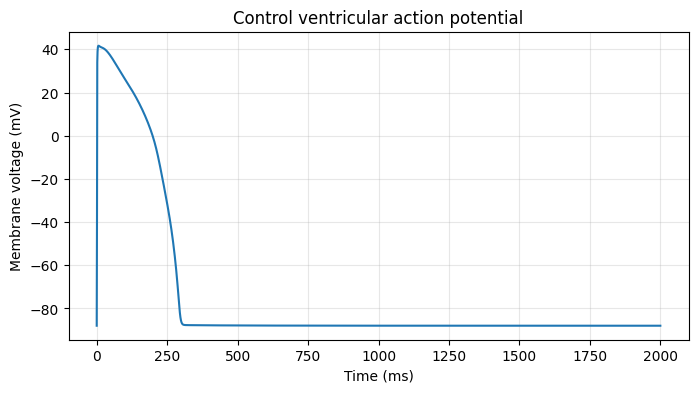

APD90: 290.0 ms


In [6]:
# confirm could simulate a cell
# simulate two beats in CiPA model
import sys
sys.path.append("/content/project/bme_507_final_project-CiPA_python")

from cipa.ap import simulate
import matplotlib.pyplot as plt

metrics, trace = simulate(beats=2, nsave=1)

plt.figure(figsize=(8, 4))
plt.plot(trace["time"], trace["v"])
plt.xlabel("Time (ms)")
plt.ylabel("Membrane voltage (mV)")
plt.title("Control ventricular action potential")
plt.grid(alpha=0.3)
plt.show()

print("APD90:", round(metrics["APD90"], 2), "ms")

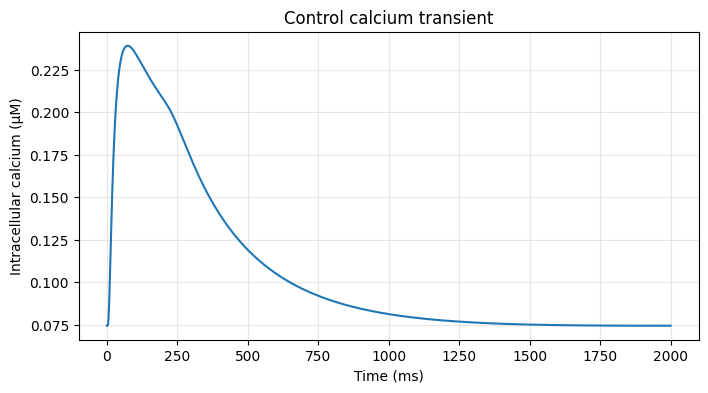

In [7]:
# plot calcium
plt.figure(figsize=(8, 4))
plt.plot(trace["time"], trace["cai"] * 1000)
plt.xlabel("Time (ms)")
plt.ylabel("Intracellular calcium (µM)")
plt.title("Control calcium transient")
plt.grid(alpha=0.3)
plt.show()

β-adrenergic model

In [9]:
# upload Gong's code
from google.colab import files
import zipfile
from pathlib import Path

uploaded = files.upload()

zip_name = "Ohara-beta-adrenergic-master.zip"

with zipfile.ZipFile(zip_name) as archive:
    archive.extractall("/content/author_model")

author_folder = Path(
    "/content/author_model/Ohara-beta-adrenergic-master"
)

print("Author's model files:")
for file in sorted((author_folder / "myfunctions").glob("*.m")):
    print(file.name)

Saving Ohara-beta-adrenergic-master.zip to Ohara-beta-adrenergic-master (1).zip
Author's model files:
Constants_SignalingMyokit.m
EffectiveFraction.m
GlobalConstants_Ephys.m
Model_Ephys.m
Model_SignalingMyokit.m
findAPD.m
fun_ORd_bAR_Myokit.m
ifthenelse.m
setInitialValues.m


In [11]:
# create python version of signaling equations
# load initial values
import re
import numpy as np
from pathlib import Path
from types import SimpleNamespace
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

source = author_folder / "myfunctions"

def translate_signaling_file(filename, header, setup, ending):
    lines = []

    for raw in (source / filename).read_text().splitlines():
        # Remove MATLAB comments and statement-ending semicolons.
        line = raw.split("%")[0].strip().rstrip(";")

        if not line or line.startswith("function ") or line == "end":
            continue
        if line.startswith("ydot = zeros"):
            continue

        # MATLAB uses ^ for powers and counts array entries from 1.
        line = line.replace("^", "**")
        line = re.sub(
            r"\b(y|ydot)\((\d+)\)",
            lambda m: f"{m[1]}[{int(m[2]) - 1}]",
            line
        )
        lines.append("    " + line)

    return header + "\n" + setup + "\n" + "\n".join(lines) + "\n" + ending

namespace = {
    "np": np,
    "SimpleNamespace": SimpleNamespace,
    "sqrt": np.emath.sqrt,
    "atan": np.arctan,
    "cos": np.cos,
    "sin": np.sin,
    "exp": np.exp,
    "log": np.log,
    "ifthenelse": lambda condition, a, b: a if condition else b,
}

code = translate_signaling_file(
    "Constants_SignalingMyokit.m",
    "def constants(iso_conc):",
    "    c = SimpleNamespace()",
    "    return c"
)

code += "\n" + translate_signaling_file(
    "Model_SignalingMyokit.m",
    "def signaling(t, y, c):",
    "    ydot = np.zeros(57)",
    "    return ydot"
)

exec(code, namespace)

constants = namespace["constants"]
signaling = namespace["signaling"]

# Read the author's 57 signaling initial values.
text = (source / "setInitialValues.m").read_text()
values = re.search(
    r"initial_Signaling\s*=\s*\[([^]]+)\]", text
).group(1)

signaling_initial = np.array([float(v) for v in values.split(",")])

assert len(signaling_initial) == 57
print("Ready: 57 signaling variables loaded.")

Ready: 57 signaling variables loaded.


ISO = 0.0 µM: simulation completed
ISO = 1.0 µM: simulation completed


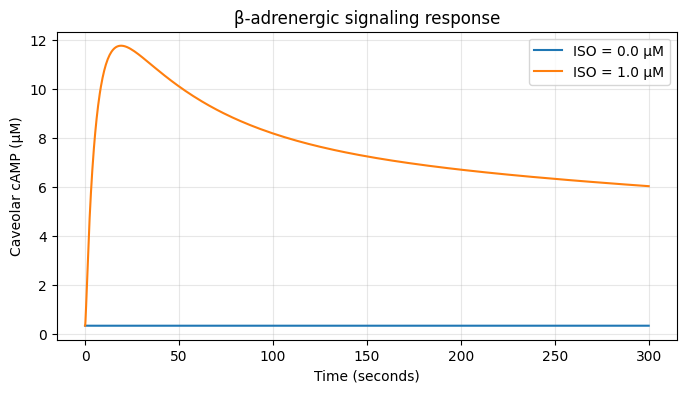

In [13]:
# test iso=0 vs iso=1 for 300 secs
# check response to iso -> plot cAMP conc
signaling_results = {}

# for each iso condition
for iso in [0.0, 1.0]:
  # run code twice
    c = constants(iso)

    solution = solve_ivp(
        lambda t, y: signaling(t, y, c),
        (0, 300_000),  # 300 seconds, expressed in milliseconds
        signaling_initial.copy(),
        method="BDF",
        rtol=1e-6,
        atol=1e-9
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    signaling_results[iso] = solution
    print(f"ISO = {iso} µM: simulation completed")

plt.figure(figsize=(8, 4))

for iso, solution in signaling_results.items():
    plt.plot(
        solution.t / 1000,
        solution.y[9], # select cAMP, 9 is cAMP
        label=f"ISO = {iso} µM"
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Caveolar cAMP (µM)")
plt.title("β-adrenergic signaling response")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

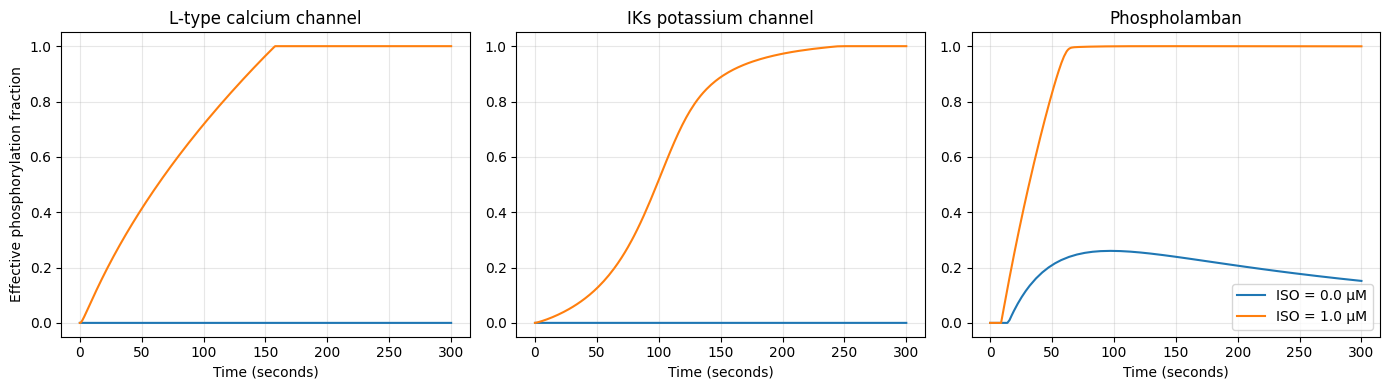

In [15]:
# check signaling reaches downstream targets
# ICaL, IK, phospholamban
def phosphorylation_outputs(solution, iso):
    c = constants(iso)
    y = solution.y

    # python counts from 0: entries 39 and 40 correspond to MATLAB signaling variables 40 and 41!!!
    # 39 is L type Ca channel
    raw_cal = np.clip(
        (y[39] + c.ICaL_arn) / c.ICaL_tot, 0.0001, 0.9999
    )
    # 40 is Iks
    raw_ks = np.clip(
        (y[40] + c.IKs_arn) / c.IKs_tot, 0.0001, 0.9999
    )

    return {
        "L-type calcium channel": np.clip(
            (raw_cal - c.ical_f_hat_ratio)
            / (0.9273 - c.ical_f_hat_ratio), 0, 1
        ),
        "IKs potassium channel": np.clip(
            (raw_ks - c.iks_f_hat_ratio)
            / (0.785 - c.iks_f_hat_ratio), 0, 1
        ),
        "Phospholamban": np.clip(
            (y[41] - 0.6591) / (0.9945 - 0.6591), 0, 1
        ),
    }

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for iso, solution in signaling_results.items():
    outputs = phosphorylation_outputs(solution, iso)

    for ax, (name, fraction) in zip(axes, outputs.items()):
        ax.plot(solution.t / 1000, fraction, label=f"ISO = {iso} µM")
        ax.set_title(name)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3)

axes[0].set_ylabel("Effective phosphorylation fraction")
axes[-1].legend()
plt.tight_layout()
plt.show()

In [17]:
# continue signal simulation to 10,000 s
for iso in [0.0, 1.0]:
    previous = signaling_results[iso]
    c = constants(iso)

    solution = solve_ivp(
        lambda t, y: signaling(t, y, c),
        (previous.t[-1], 10_000_000),  # End at 10,000 seconds
        previous.y[:, -1],
        method="BDF",
        rtol=1e-6,
        atol=1e-9
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    signaling_results[iso] = solution

    print(f"\nISO = {iso} µM")
    print(f"Final caveolar cAMP: {solution.y[9, -1]:.4f} µM")

    for name, fraction in phosphorylation_outputs(solution, iso).items():
        print(f"{name}: {fraction[-1]:.4f}")


ISO = 0.0 µM
Final caveolar cAMP: 0.3444 µM
L-type calcium channel: 0.0000
IKs potassium channel: 0.0001
Phospholamban: 0.0000

ISO = 1.0 µM
Final caveolar cAMP: 2.9371 µM
L-type calcium channel: 0.9998
IKs potassium channel: 0.9546
Phospholamban: 0.9966


In [18]:
# load python translation of Gong model
# actual equations are in gong_beta.py!!!
# separate from Alyssa's CiPA
from google.colab import files
import zipfile
import sys

uploaded = files.upload()

with zipfile.ZipFile("Beta_Adrenergic_Starter.zip") as archive:
    archive.extractall("/content")

sys.path.insert(0, "/content/beta_adrenergic_starter")

print("Coupled model ready!")

Saving Beta_Adrenergic_Starter.zip to Beta_Adrenergic_Starter.zip
Coupled model ready!


Running ISO = 0.0 uM ...
Last-beat APD90: 229.59 ms
Running ISO = 1.0 uM ...
Last-beat APD90: 172.84 ms


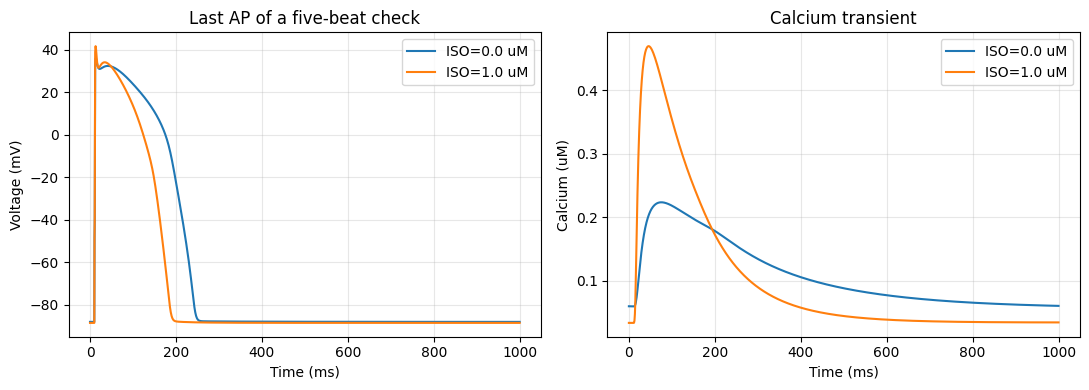

<Figure size 640x480 with 0 Axes>

In [19]:
# test run: 5 paced beats at 1hz, iso = 0 vs 1um
%run /content/beta_adrenergic_starter/run_example.py

ISO 0.0 µM | Beat 10 | APD90 231.21 ms | Ca amplitude 0.2315 µM
ISO 0.0 µM | Beat 15 | APD90 229.72 ms | Ca amplitude 0.2992 µM
ISO 0.0 µM | Beat 20 | APD90 227.55 ms | Ca amplitude 0.3554 µM
ISO 0.0 µM | Beat 25 | APD90 225.99 ms | Ca amplitude 0.3987 µM
ISO 1.0 µM | Beat 10 | APD90 167.58 ms | Ca amplitude 0.6935 µM
ISO 1.0 µM | Beat 15 | APD90 167.39 ms | Ca amplitude 0.7748 µM
ISO 1.0 µM | Beat 20 | APD90 167.65 ms | Ca amplitude 0.8516 µM
ISO 1.0 µM | Beat 25 | APD90 167.98 ms | Ca amplitude 0.9218 µM


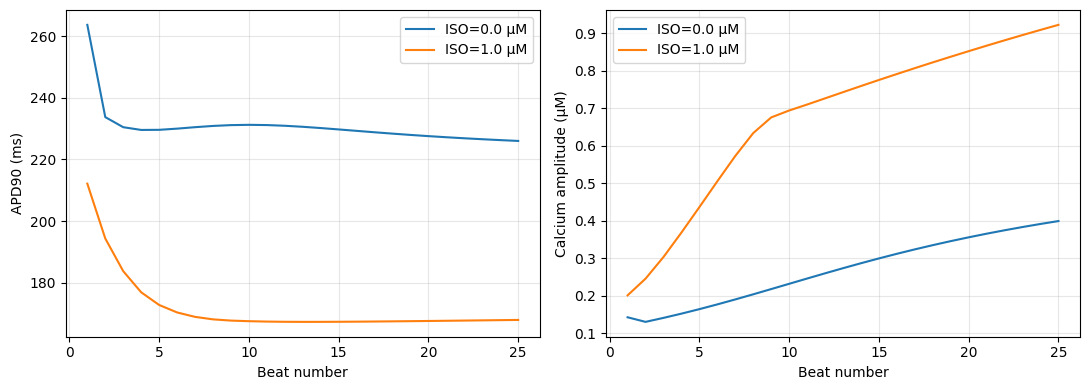

In [20]:
# continue model for 20 more beats, 25 total
# record APD90 and Ca amplitude
import numpy as np
import matplotlib.pyplot as plt
from gong_beta import run_cell

for iso in [0.0, 1.0]:
    # copy ealier measurements
    history = results[iso]["history"].copy()
    state = results[iso]["state"].copy()

    # add 20 beats, checking progress every 5 beats
    for chunk in range(4):
        next_run = run_cell(
            iso=iso,
            beats=5, # number of beats in each chunk
            pcl=1000, # pacing cycle length, 1000ms = 1hz
            state=state
        )

        new_history = next_run["history"].copy()
        new_history[:, 0] += history[-1, 0]
        history = np.vstack([history, new_history])
        state = next_run["state"].copy()

        print(
            f"ISO {iso} µM | Beat {int(history[-1, 0])} | "
            f"APD90 {history[-1, 1]:.2f} ms | "
            f"Ca amplitude {history[-1, 2]:.4f} µM",
            flush=True
        )

    results[iso] = next_run
    results[iso]["history"] = history

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for iso, result in results.items():
    h = result["history"]
    axes[0].plot(h[:, 0], h[:, 1], label=f"ISO={iso} µM")
    axes[1].plot(h[:, 0], h[:, 2], label=f"ISO={iso} µM")

axes[0].set(xlabel="Beat number", ylabel="APD90 (ms)")
axes[1].set(xlabel="Beat number", ylabel="Calcium amplitude (µM)")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

ISO 0.0 µM | Beat 35 | APD90 224.15 ms | Ca amplitude 0.4561 µM
ISO 0.0 µM | Beat 45 | APD90 223.03 ms | Ca amplitude 0.4894 µM
ISO 0.0 µM | Beat 55 | APD90 222.17 ms | Ca amplitude 0.5098 µM
ISO 0.0 µM | Beat 65 | APD90 221.45 ms | Ca amplitude 0.5233 µM
ISO 0.0 µM | Beat 75 | APD90 220.80 ms | Ca amplitude 0.5330 µM
ISO 0.0 µM | Beat 85 | APD90 220.22 ms | Ca amplitude 0.5405 µM
ISO 0.0 µM | Beat 95 | APD90 219.69 ms | Ca amplitude 0.5466 µM
ISO 0.0 µM | Beat 105 | APD90 219.20 ms | Ca amplitude 0.5519 µM
ISO 0.0 µM | Beat 115 | APD90 218.75 ms | Ca amplitude 0.5566 µM
ISO 0.0 µM | Beat 125 | APD90 218.34 ms | Ca amplitude 0.5608 µM
ISO 1.0 µM | Beat 35 | APD90 168.67 ms | Ca amplitude 1.0441 µM
ISO 1.0 µM | Beat 45 | APD90 169.28 ms | Ca amplitude 1.1453 µM
ISO 1.0 µM | Beat 55 | APD90 169.78 ms | Ca amplitude 1.2290 µM
ISO 1.0 µM | Beat 65 | APD90 170.19 ms | Ca amplitude 1.2979 µM
ISO 1.0 µM | Beat 75 | APD90 170.51 ms | Ca amplitude 1.3542 µM
ISO 1.0 µM | Beat 85 | APD90 170.76 m

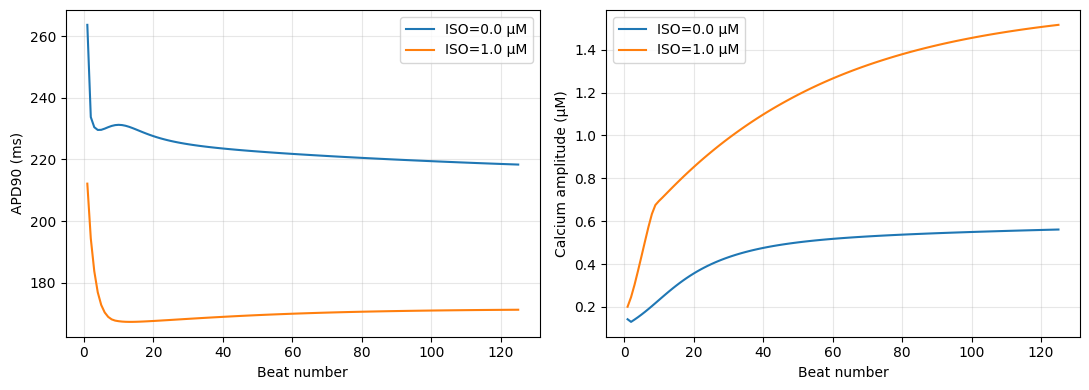

In [ ]:
# continue anoth 100 beats, total 125 beats
# record APD90 and Ca amplitude
for iso in [0.0, 1.0]:
    history = results[iso]["history"].copy()
    state = results[iso]["state"].copy()

    # Run another 100 beats in groups of 10.
    for chunk in range(10):
        next_run = run_cell(
            iso=iso,
            beats=10,
            pcl=1000,
            state=state
        )

        new_history = next_run["history"].copy()
        new_history[:, 0] += history[-1, 0]
        history = np.vstack([history, new_history])
        state = next_run["state"].copy()

        print(
            f"ISO {iso} µM | Beat {int(history[-1, 0])} | "
            f"APD90 {history[-1, 1]:.2f} ms | "
            f"Ca amplitude {history[-1, 2]:.4f} µM",
            flush=True
        )

        # Keep progress available after each completed group.
        results[iso] = next_run
        results[iso]["history"] = history.copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for iso, result in results.items():
    h = result["history"]
    axes[0].plot(h[:, 0], h[:, 1], label=f"ISO={iso} µM")
    axes[1].plot(h[:, 0], h[:, 2], label=f"ISO={iso} µM")

axes[0].set(xlabel="Beat number", ylabel="APD90 (ms)")
axes[1].set(xlabel="Beat number", ylabel="Calcium amplitude (µM)")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# save simulation for back-up!!!
from pathlib import Path
import numpy as np
import json
import zipfile
from google.colab import files

folder = Path("/content/beta_progress")
folder.mkdir(exist_ok=True)

for iso, result in results.items():
    label = "ISO0" if iso == 0 else "ISO1"

    np.savez_compressed(
        folder / f"{label}_checkpoint.npz",
        **result
    )

    np.savetxt(
        folder / f"{label}_history.csv",
        result["history"],
        delimiter=",",
        header="beat,APD90_ms,calcium_amplitude_uM",
        comments=""
    )

fig.savefig(folder / "conditioning_history.png",
            dpi=200, bbox_inches="tight")

metadata = {
    "model": "Exploratory Python translation of Gong et al. 2020",
    "pacing_cycle_length_ms": 1000,
    "ISO_conditions_uM": [0, 1],
    "signaling_preconditioning_seconds": 10000,
    "status": "Electrical conditioning ongoing; MATLAB parity unverified",
    "history_columns": ["beat", "APD90_ms", "calcium_amplitude_uM"]
}
(folder / "settings.json").write_text(json.dumps(metadata, indent=2))

zip_path = Path("/content/Beta_Progress_Backup.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in folder.iterdir():
        archive.write(path, arcname=path.name)

files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>